# 04 · Robustness: parameter sensitivity and the Deflated Sharpe Ratio

**Questions:** do the results of notebooks 01-03 depend on the exact parameter values that were chosen? And once every configuration tried in the project is counted, is the best one distinguishable from the best of that many strategies with no skill?

**Short answer:** the conclusions hold, and one of them gets weaker for the strategy.

- **Trend following sits on a plateau.** Any window from 150 to 250 sessions gives a Sharpe of 0.78 to 0.81; the 200 fixed in advance is not special.
- **Momentum's default was the luckiest cell of its grid.** 12-1 with the top 3 is the best of 30 combinations (0.67); its neighbours average 0.58 and 28 of the 30 cells are below equal weight (0.64). Notebook 01 said momentum matches equal weight. The grid says that was the favourable end of what momentum does here.
- **Mean reversion is a smooth slope with no peak**, and **pairs trading is noise around zero** (17 of 20 cells negative).
- **The best configuration found, trend following with a 175-day window (Sharpe 0.81), does not survive the correction for 98 trials**: its Deflated Sharpe Ratio is 0.54, against the 0.95 usually asked for. Measured against equal weight instead of cash, the best of the sector trials has a DSR of about 0.5: exactly what the luckiest of 70 skill-less variations would show.

Rules of this notebook:
- It only imports from `backtester` and presents results; the logic lives in `src/` with its tests.
- The grids are a diagnostic, not a search. The headline results of the project remain those of the parameters fixed in advance in notebooks 01-03. Nothing is re-tuned here.
- Every cell of every grid is a new trial and is counted as one in section 2.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from backtester import ProportionalCosts, run_backtest
from backtester.data import load_prices
from backtester.metrics import sharpe
from backtester.report import plot_sharpe_heatmap
from backtester.sensitivity import default_in_context, run_grid
from backtester.significance import deflated_sharpe_ratio, effective_trials, return_moments
from backtester.strategies import (
    CrossSectionalMomentum,
    MeanReversion,
    PairsTrading,
    TrendFollowing,
)
from backtester.strategy import BuyAndHold, EqualWeight

SECTOR_ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
PAIRS = [("KO", "PEP"), ("XOM", "CVX"), ("GLD", "GDX"), ("EWA", "EWC")]
TICKERS = [ticker for pair in PAIRS for ticker in pair]
END = "2026-10-31"  # fixed end date: reproducible numbers
COSTS = ProportionalCosts(bps=5)
# The values fixed in advance in notebooks 01-03, before any result was seen.
DEFAULTS = {
    "Momentum": (252, 3),
    "Mean reversion": (20, 3),
    "Trend following": 200,
    "Pairs trading": (252, 2.0),
}
IMG_DIR = Path("../docs/img")

In [2]:
sectors = load_prices(SECTOR_ETFS, start="2005-01-01", end=END)
pair_prices = load_prices(TICKERS, start="2006-05-22", end=END)
print(f"Sectors: {sectors.shape[0]} sessions from {sectors.index[0].date()}")
print(f"Pairs:   {pair_prices.shape[0]} sessions from {pair_prices.index[0].date()}")

Sectors: 5492 sessions from 2005-01-03
Pairs:   5144 sessions from 2006-05-22


## 1. Parameter sensitivity

Same data, same costs (5 bps) and same rebalancing as in notebooks 01-03: monthly for the three sector strategies and none for pairs trading, which gives its own orders (a monthly calendar would delay its entries and exits).

| Strategy | Parameters varied | Fixed in advance |
|---|---|---|
| Momentum | lookback {63, 126, 189, 252, 315, 378} × top_n {1..5}; skip stays at 21 | 252, 3 |
| Mean reversion | lookback {5, 10, 20, 40, 60} × top_n {1..5} | 20, 3 |
| Trend following | moving-average window {50, ..., 300} | 200 |
| Pairs trading (the four pairs together) | formation window {126, 189, 252, 378, 504} × entry z {1.5, 2, 2.5, 3} | 252, 2.0 |

The grid values were written down before running anything, on round numbers around each default, so that each default has neighbours on both sides.

**The period is slightly shorter than before.** All cells of a grid must cover the same days, and the slowest cell sets the start: an 18-month momentum lookback for the sector grids (2006-08-01, six months later than in notebooks 01-02) and a two-year formation window for pairs (2008-05-21, a year later than in notebook 03). The Sharpe ratios of the defaults are therefore close to, but not the same as, those reported earlier.

In [3]:
def momentum(lookback: int, top_n: int) -> CrossSectionalMomentum:
    return CrossSectionalMomentum(lookback=lookback, top_n=top_n)  # skip stays at 21


def mean_reversion(lookback: int, top_n: int) -> MeanReversion:
    return MeanReversion(lookback=lookback, top_n=top_n)


top_n = [1, 2, 3, 4, 5]
grids = {
    "Momentum": run_grid(
        sectors, momentum, {"lookback": [63, 126, 189, 252, 315, 378], "top_n": top_n}, COSTS, "ME"
    )
}
# The slowest cell of all (momentum with an 18-month lookback) sets the start for the three
# sector grids, so that they and the equal-weight reference cover exactly the same days.
start = grids["Momentum"].start
grids["Mean reversion"] = run_grid(
    sectors,
    mean_reversion,
    {"lookback": [5, 10, 20, 40, 60], "top_n": top_n},
    COSTS,
    "ME",
    start=start,
)
grids["Trend following"] = run_grid(
    sectors,
    TrendFollowing,
    {"window": [50, 75, 100, 125, 150, 175, 200, 225, 250, 300]},
    COSTS,
    "ME",
    start=start,
)
equal_weight = run_backtest(sectors, EqualWeight(), COSTS, rebalance="ME").since(start)
print(f"Sector grids: {start.date()} to {sectors.index[-1].date()}")
print(f"Equal weight over the same period: Sharpe {sharpe(equal_weight.returns):.2f}")

Sector grids: 2006-08-01 to 2026-10-30
Equal weight over the same period: Sharpe 0.64


In [4]:
def pairs_trading(formation: int, entry_z: float) -> PairsTrading:
    return PairsTrading(PAIRS, formation=formation, entry_z=entry_z)


formations = [126, 189, 252, 378, 504]
# Pairs trading can wait a long time for its first trade, so the start is given: the first
# close with a full formation window for the longest window in the grid.
grids["Pairs trading"] = run_grid(
    pair_prices,
    pairs_trading,
    {"formation": formations, "entry_z": [1.5, 2.0, 2.5, 3.0]},
    COSTS,
    rebalance=None,
    start=pair_prices.index[max(formations) - 1],
)
pairs_start = grids["Pairs trading"].start
print(f"Pairs grid: {pairs_start.date()} to {pair_prices.index[-1].date()}")

Pairs grid: 2008-05-21 to 2026-10-30


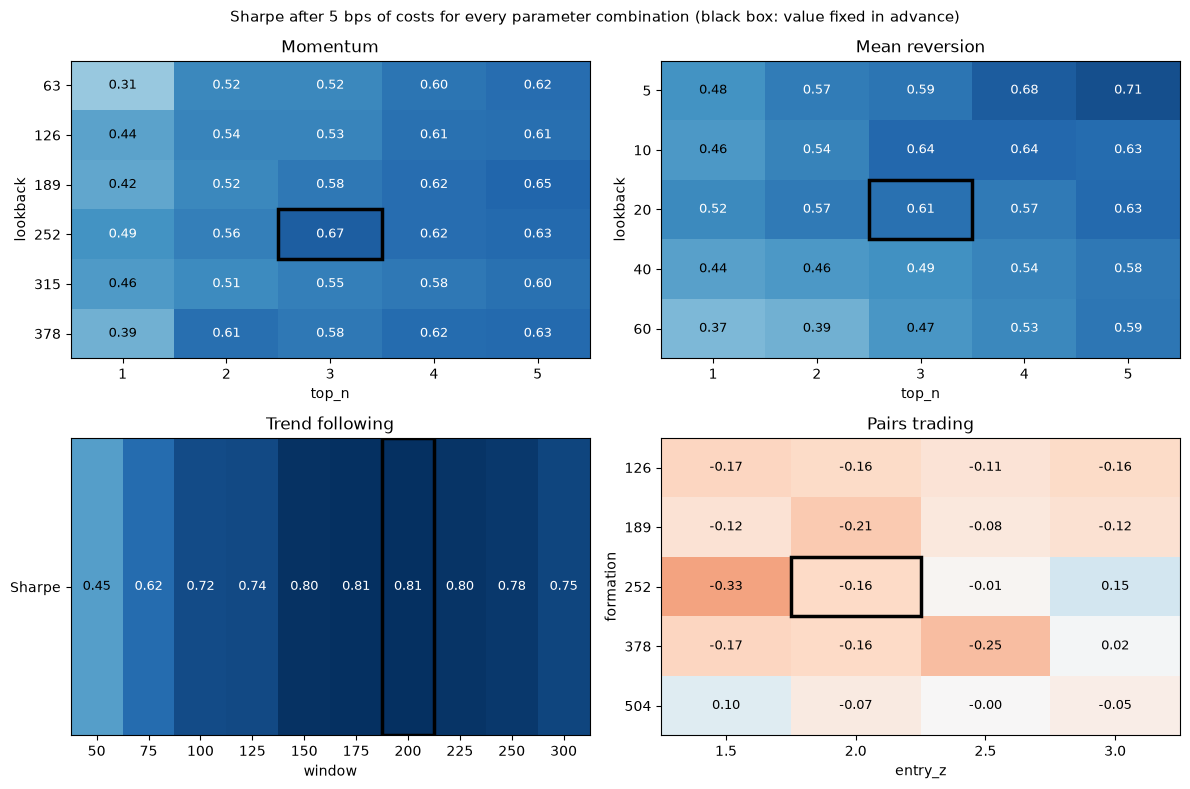

In [5]:
tables = {name: grid.sharpe.unstack() for name, grid in grids.items() if name != "Trend following"}
tables["Trend following"] = grids["Trend following"].sharpe.to_frame("Sharpe").T
marks = {**DEFAULTS, "Trend following": ("Sharpe", DEFAULTS["Trend following"])}
limit = max(table.abs().max().max() for table in tables.values())  # one colour scale for all

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes.flat, grids, strict=True):
    plot_sharpe_heatmap(tables[name], default=marks[name], title=name, limit=limit, ax=ax)
axes[1, 0].set_ylabel("")
fig.suptitle(
    "Sharpe after 5 bps of costs for every parameter combination (black box: value fixed in "
    "advance)",
    fontsize=11,
)
fig.tight_layout()
IMG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG_DIR / "sensitivity.png", dpi=150)
plt.show()

In [6]:
context = pd.DataFrame(
    {name: default_in_context(grid.sharpe, DEFAULTS[name]) for name, grid in grids.items()}
)
context.loc["Default minus neighbours mean"] = (
    context.loc["Default"] - context.loc["Neighbours mean"]
)
context.loc["Benchmark Sharpe, same period"] = [sharpe(equal_weight.returns)] * 3 + [0.0]
context.round(2)

,Momentum,Mean reversion,Trend following,Pairs trading
Default,0.67,0.61,0.81,-0.16
Rank,1.00,7.00,2.00,15.00
Cells,30.00,25.00,10.00,20.00
Grid min,0.31,0.37,0.45,-0.33
Grid median,0.58,0.57,0.77,-0.12
Grid max,0.67,0.71,0.81,0.15
Neighbours mean,0.58,0.57,0.81,-0.18
Neighbours min,0.55,0.49,0.80,-0.33
Share of cells above zero,1.00,1.00,1.00,0.15
Default minus neighbours mean,0.09,0.04,0.01,0.01


In [7]:
below = {
    name: (grids[name].sharpe < sharpe(equal_weight.returns)).mean()
    for name in ("Momentum", "Mean reversion", "Trend following")
}
print("Share of cells with a lower Sharpe than equal weight over the same period:")
print(pd.Series(below).round(2).to_string())
in_trade = (grids["Pairs trading"].returns != 0).mean().unstack()
print("\nPairs trading, share of days with a non-zero return (a trade open):")
in_trade.round(3)

Share of cells with a lower Sharpe than equal weight over the same period:
Momentum           0.93
Mean reversion     0.92
Trend following    0.20

Pairs trading, share of days with a non-zero return (a trade open):


entry_z,1.5,2.0,2.5,3.0
formation,,,,
126,0.152,0.113,0.077,0.043
189,0.149,0.103,0.059,0.033
252,0.133,0.095,0.057,0.032
378,0.103,0.071,0.030,0.012
504,0.150,0.081,0.059,0.037


**Reading the grids.** "Neighbours" are the cells one step away along a single parameter. A plateau shows as a default close to the mean of its neighbours; a spike as a default well above it. For scale, the standard error of a Sharpe ratio of 0.6 over 20 years is about 0.24, so differences of a few hundredths between cells mean nothing by themselves.

| Strategy | Default | Rank in grid | Neighbours mean | Grid median | Verdict |
|---|---|---|---|---|---|
| Momentum | 0.67 | 1 of 30 | 0.58 | 0.58 | **Local peak on a flat surface** |
| Mean reversion | 0.61 | 7 of 25 | 0.57 | 0.57 | **Smooth slope, no peak** |
| Trend following | 0.81 | 2 of 10 | 0.81 | 0.77 | **Plateau** |
| Pairs trading | −0.16 | 15 of 20 | −0.18 | −0.12 | **Noise around zero** |

- **Momentum: the default is the single best cell.** It is 0.09 above the mean of its four neighbours and above every other combination. This is not a dramatic spike: the whole surface is flat (0.5 to 0.65 for any top_n of 2 or more) and 0.09 is well inside the noise. But it changes how notebook 01 should be read. There, momentum had the same Sharpe as equal weight; here 28 of the 30 cells are below equal weight over the same period (0.64) and the median cell is at 0.58. The pre-fixed parameters were not tuned, they were the textbook ones, and they happened to land on the most favourable spot. A typical momentum configuration on these nine sectors does slightly worse than holding them all.
- **Mean reversion: a slope towards equal weight.** The Sharpe rises with more names held and with shorter lookbacks, with no isolated peak, and 23 of 25 cells are below equal weight. Holding 5 of 9 sectors with a signal that changes every few days is close to holding all of them, so the best corner of the grid is the one that looks most like the benchmark.
- **Trend following: a plateau from 150 to 250.** Five neighbouring windows give 0.78 to 0.81, and it only degrades for fast windows (0.45 at 50 sessions, where the rule trades on noise and monthly rebalancing reacts late). The result of notebook 02 does not depend on having chosen 200. That makes it robust to the parameter; it does not make it significant, and the caveats of notebook 02 stand: it is a portfolio that is 75% invested, and its edge rests on 2008.
- **Pairs trading: no structure.** 17 of 20 cells are negative and the three positive ones are small (0.15 at best). Two of them are in the strictest entry column, which has a trade open on 1% to 4% of the days, so they rest on a handful of trades. A longer formation window, which should give the cointegration test more power, does not help. There is no neighbouring parameter set where the strategy of notebook 03 works.

## 2. How many configurations has this project tried?

The best of many backtests looks good partly because it was picked. To correct for that, every result that was looked at has to be counted, not only those that were reported. The rule used here: **a trial is a distinct combination of strategy, parameters, universe, costs, rebalancing and engine version whose performance was seen.**

- The 85 grid cells above. They include the four defaults of notebooks 01-03, which are the same configurations and are counted once.
- Notebook 01 also ran momentum at 0 and 20 bps of costs, the equal-weight benchmark and a buy-and-hold reference: 4.
- Notebook 02 added nothing beyond the three defaults and the same benchmark.
- Notebook 03 also ran each of the four pairs alone and an equal-weight portfolio of the eight tickers as a reference: 5.
- The first version of notebook 01 ran momentum at 0, 5 and 20 bps and its benchmark on the engine before weight drift was modelled. Those figures were seen (notebook 01 quotes them) and that engine no longer exists, so they are counted but cannot be re-run: 4.

Not counted: the block lengths tried for the bootstrap in notebook 01 and the "without 2008" Sharpe ratios in notebook 02 (same return series, a different way of looking at them), and runs on synthetic data in the tests. Benchmarks are counted, which is the conservative choice; the table in section 3 also shows the figure without them.

In [8]:
def label(name: str, grid_index: pd.Index) -> list[str]:
    return [f"{name} {cell}" for cell in grid_index]


# 1. The 85 grid cells. They include the four defaults of notebooks 01-03.
trial_returns = pd.concat(
    [
        grid.returns.set_axis(label(name, grid.returns.columns), axis=1)
        for name, grid in grids.items()
    ],
    axis=1,
)
family = pd.Series(
    [name for name, grid in grids.items() for _ in grid.returns.columns],
    index=trial_returns.columns,
)
universe = family.where(family == "Pairs trading", "Sectors").replace("Pairs trading", "Pairs")

# 2. What notebooks 01-03 ran besides those defaults, over the periods used there.
first_sector_day = run_backtest(sectors, momentum(252, 3), COSTS, rebalance="ME").first_active
entry = sectors.index[sectors.index.get_loc(first_sector_day) - 1]
first_pairs_day = pair_prices.index[252 - 1]
earlier = {
    "Momentum (252, 3), 0 bps": run_backtest(
        sectors, momentum(252, 3), ProportionalCosts(bps=0), rebalance="ME"
    ).since(first_sector_day),
    "Momentum (252, 3), 20 bps": run_backtest(
        sectors, momentum(252, 3), ProportionalCosts(bps=20), rebalance="ME"
    ).since(first_sector_day),
    "Equal weight, sectors": run_backtest(sectors, EqualWeight(), COSTS, rebalance="ME").since(
        first_sector_day
    ),
    "Buy & hold, sectors": run_backtest(sectors.loc[entry:], BuyAndHold(), COSTS).since(
        first_sector_day
    ),
    "Equal weight, pair tickers": run_backtest(
        pair_prices, EqualWeight(), COSTS, rebalance="ME"
    ).since(first_pairs_day),
}
for y, x in PAIRS:
    earlier[f"Pairs trading, {y}/{x} alone"] = run_backtest(
        pair_prices, PairsTrading([(y, x)]), COSTS
    ).since(first_pairs_day)
BENCHMARKS = ["Equal weight, sectors", "Buy & hold, sectors", "Equal weight, pair tickers"]

for name, result in earlier.items():
    trial_returns[name] = result.returns
    universe[name] = "Pairs" if "air" in name else "Sectors"
    if name in BENCHMARKS:
        family[name] = "Benchmark"
    else:
        family[name] = "Pairs trading" if universe[name] == "Pairs" else "Momentum, other costs"

# 3. Results that were looked at and cannot be re-run: the engine before weight drift
#    (notebook 01, first version): momentum at 0, 5 and 20 bps and its benchmark.
NOT_REPRODUCIBLE = 4

counts = pd.Series(
    {
        "Momentum grid (lookback x top_n)": 30,
        "Mean reversion grid (lookback x top_n)": 25,
        "Trend following grid (window)": 10,
        "Pairs trading grid (formation x entry z)": 20,
        "Notebook 01: momentum at 0 and 20 bps, equal weight, buy & hold": 4,
        "Notebook 03: each pair alone (4) and equal weight of the 8 tickers": 5,
        "Notebook 01, engine before weight drift (not reproducible)": NOT_REPRODUCIBLE,
    },
    name="Trials",
)
N_TRIALS = int(counts.sum())
assert trial_returns.shape[1] == N_TRIALS - NOT_REPRODUCIBLE
counts.to_frame().assign(Total=lambda table: table["Trials"].cumsum())

,Trials,Total
Momentum grid (lookback x top_n),30,30
Mean reversion grid (lookback x top_n),25,55
Trend following grid (window),10,65
Pairs trading grid (formation x entry z),20,85
"Notebook 01: momentum at 0 and 20 bps, equal weight, buy & hold",4,89
Notebook 03: each pair alone (4) and equal weight of the 8 tickers,5,94
"Notebook 01, engine before weight drift (not reproducible)",4,98


## 3. Deflated Sharpe Ratio of the best configuration

The Deflated Sharpe Ratio (Bailey & López de Prado, 2014) is the probability that the true Sharpe ratio of the selected strategy is above $SR_0$, the Sharpe ratio that the best of $N$ strategies with no skill is expected to show:

$$SR_0 = \sqrt{V}\left[(1-\gamma)\,\Phi^{-1}\!\left(1-\tfrac{1}{N}\right) + \gamma\,\Phi^{-1}\!\left(1-\tfrac{1}{N e}\right)\right], \qquad DSR = \Phi\!\left(\frac{(\widehat{SR}-SR_0)\sqrt{T-1}}{\sqrt{1-\gamma_3\widehat{SR}+\frac{\gamma_4-1}{4}\widehat{SR}^2}}\right)$$

$V$ is the variance of the Sharpe ratio across the trials, $\gamma$ the Euler-Mascheroni constant, $T$ the number of daily returns of the selected strategy and $\gamma_3$, $\gamma_4$ their skewness and kurtosis (3 for a normal). The formula holds for per-period Sharpe ratios; `deflated_sharpe_ratio` takes the annualized ones used everywhere else in the project and converts them, and a test checks that both routes agree and that the numerical example of the paper is reproduced (DSR = 0.9004). A DSR above 0.95 is the usual bar.

The inputs come from the trials themselves: 94 of the 98 can be re-run, each over its own period, and give $V$. The best configuration is chosen among those that are not benchmarks.

In [9]:
trial_sharpes = trial_returns.apply(sharpe)  # annualized; each trial over its own period
candidates = trial_sharpes.drop(BENCHMARKS)
best = candidates.idxmax()
best_returns = trial_returns[best].dropna()
skew, kurtosis = return_moments(best_returns)  # kurtosis with normal = 3, not excess

print(f"Best configuration: {best}, Sharpe {trial_sharpes[best]:.3f}")
print(
    f"Daily returns: {len(best_returns)} observations, skewness {skew:.2f}, kurtosis {kurtosis:.1f}"
)
print(f"Trials with a Sharpe ratio: {trial_sharpes.notna().sum()} of {len(trial_sharpes)}")
trial_sharpes.groupby(family).describe()[["count", "mean", "std", "min", "max"]].round(3)

Best configuration: Trend following 175, Sharpe 0.813
Daily returns: 5095 observations, skewness -0.56, kurtosis 6.6
Trials with a Sharpe ratio: 94 of 94


,count,mean,std,min,max
Benchmark,3.0,0.622,0.048,0.567,0.655
Mean reversion,25.0,0.549,0.087,0.366,0.715
Momentum,30.0,0.554,0.084,0.305,0.669
"Momentum, other costs",2.0,0.655,0.039,0.628,0.683
Pairs trading,24.0,-0.083,0.137,-0.326,0.209
Trend following,10.0,0.729,0.115,0.446,0.813


In [10]:
def dsr_row(n_trials: float, sharpes: pd.Series) -> dict:
    result = deflated_sharpe_ratio(
        trial_sharpes[best],
        n_trials=n_trials,
        sharpe_variance=sharpes.var(ddof=1) if n_trials > 1 else 0.0,
        skew=skew,
        kurtosis=kurtosis,
        n_obs=len(best_returns),
    )
    return {
        "Trials (N)": n_trials,
        "Std of Sharpe across trials": sharpes.std(ddof=1) if n_trials > 1 else 0.0,
        "Expected max Sharpe with no skill": result.expected_max_sharpe,
        "Sharpe of the best": result.sharpe,
        "DSR": result.dsr,
    }


with_sharpe = trial_sharpes.dropna()
n_effective = effective_trials(trial_returns[with_sharpe.index])
sector = with_sharpe[universe[with_sharpe.index] == "Sectors"]

dsr = pd.DataFrame(
    {
        "No correction (a single trial)": dsr_row(1, with_sharpe),
        f"All {N_TRIALS} trials, as if independent": dsr_row(N_TRIALS, with_sharpe),
        f"Without the {len(BENCHMARKS) + 1} benchmark runs": dsr_row(
            N_TRIALS - len(BENCHMARKS) - 1, with_sharpe.drop(BENCHMARKS)
        ),
        "Effective number of trials (correlation)": dsr_row(n_effective, with_sharpe),
        "Sector trials only": dsr_row(len(sector) + NOT_REPRODUCIBLE, sector),
    }
).T
dsr.round(3)

,Trials (N),Std of Sharpe across trials,Expected max Sharpe with no skill,Sharpe of the best,DSR
No correction (a single trial),1.00,0.000,0.000,0.813,1.000
"All 98 trials, as if independent",98.00,0.314,0.791,0.813,0.538
Without the 4 benchmark runs,94.00,0.316,0.793,0.813,0.535
Effective number of trials (correlation),50.64,0.314,0.715,0.813,0.667
Sector trials only,73.00,0.108,0.262,0.813,0.993


**What the table says.**

- **Without correction, the best configuration looks certain** (the first row is the probability that its Sharpe ratio is above zero, taken as if it were the only thing ever run).
- **Counting all 98 trials, the DSR is 0.54.** The best of 98 skill-less strategies whose Sharpe ratios are as spread out as these would be expected to show 0.79, and trend following with a 175-day window shows 0.81. That is a coin flip, far from 0.95.
- **Neighbouring grid cells are not independent trials.** With the effective number of trials implied by the average correlation between them (about 51), the DSR is 0.67. Still far from 0.95.
- **The answer depends heavily on $V$, and here $V$ mixes two different things.** The trials are two clusters: sector portfolios around 0.6 and pairs trading around −0.1. Most of the spread (a standard deviation of 0.31) is the distance between the clusters, not luck within a family. With the sector trials alone the spread is 0.11, the hurdle drops to 0.26 and the DSR is 0.99.

That last number is not good news, it is the answer to an uninteresting question. The DSR measures the Sharpe ratio against **zero**. Every sector trial is a long-only equity portfolio, and US equities earned a Sharpe ratio of about 0.6 over these 20 years: equal weight, with no strategy at all, has 0.64. A DSR of 0.99 on sector trials says that being long equities paid, which was never in doubt. The question this project has asked since notebook 01 is whether a strategy beats holding the sectors.

### Against equal weight

Same calculation on the **active return**: the daily return of each sector trial minus that of equal weight on the same days. A positive Sharpe ratio of that series means the trial beat the benchmark after adjusting for the risk of the difference. Pairs trading is left out because its benchmark is cash.

In [11]:
# Sector trials over the common period, minus equal weight on the same days.
since_start = {
    "Momentum (252, 3), 0 bps": ProportionalCosts(bps=0),
    "Momentum (252, 3), 20 bps": ProportionalCosts(bps=20),
}
sector_returns = pd.concat(
    [trial_returns.loc[start:, universe[(universe == "Sectors") & family.isin(grids)].index]]
    + [
        run_backtest(sectors, momentum(252, 3), cost, rebalance="ME")
        .since(start)
        .returns.rename(name)
        for name, cost in since_start.items()
    ],
    axis=1,
)
active = sector_returns.sub(equal_weight.returns, axis=0)
active_sharpes = active.apply(sharpe)
best_active = active_sharpes.idxmax()
active_skew, active_kurtosis = return_moments(active[best_active])
# The three momentum runs on the old engine were also comparisons against a benchmark.
n_active = active.shape[1] + NOT_REPRODUCIBLE - 1


def active_row(n_trials: float) -> dict:
    result = deflated_sharpe_ratio(
        active_sharpes[best_active],
        n_trials=n_trials,
        sharpe_variance=active_sharpes.var(ddof=1) if n_trials > 1 else 0.0,
        skew=active_skew,
        kurtosis=active_kurtosis,
        n_obs=len(active),
    )
    return {
        "Trials (N)": n_trials,
        "Expected max Sharpe with no skill": result.expected_max_sharpe,
        "Sharpe of the best": result.sharpe,
        "DSR": result.dsr,
    }


print(f"Best against equal weight: {best_active}")
print(f"Sharpe of its return minus equal weight: {active_sharpes[best_active]:.3f}")
print(
    f"Share of the {active.shape[1]} sector trials that beat equal weight: "
    f"{(active_sharpes > 0).mean():.0%}"
)
pd.DataFrame(
    {
        "No correction (a single trial)": active_row(1),
        f"All {n_active} sector trials, as if independent": active_row(n_active),
        "Effective number of trials (correlation)": active_row(effective_trials(active)),
    }
).T.round(3)

Best against equal weight: Mean reversion (5, 5)
Sharpe of its return minus equal weight: 0.347
Share of the 67 sector trials that beat equal weight: 16%


,Trials (N),Expected max Sharpe with no skill,Sharpe of the best,DSR
No correction (a single trial),1.000,0.000,0.347,0.940
"All 70 sector trials, as if independent",70.000,0.356,0.347,0.484
Effective number of trials (correlation),51.138,0.339,0.347,0.515


Against equal weight the best of the sector trials is mean reversion with a 5-day lookback holding 5 of 9 sectors, with an active Sharpe of 0.35. Taken alone that would look promising (a probability of 0.94 of being above zero). But it is the best of 70, only 16% of the trials beat equal weight at all, and the best of 70 skill-less variations would be expected to show 0.36. **The DSR is about 0.5: the best result of the project against its benchmark is what luck alone would produce.**

## 4. Conclusions

- **Sensitivity.** Trend following is robust to its one parameter. Momentum's default was the best cell of its grid, so "momentum matches equal weight" was the favourable reading: most momentum configurations are slightly behind it. Mean reversion and pairs trading show nothing that a different parameter would rescue.
- **Selection.** 98 configurations have been looked at. The best Sharpe ratio among them (0.81) has a DSR of 0.54 counting all trials and 0.67 with the effective number of trials; the best result against equal weight has a DSR of about 0.5. None is near 0.95.
- **These are the same conclusions as before, reached by a different route.** Notebooks 01-03 tested pre-fixed parameters once and found nothing significant with a bootstrap. This notebook does the opposite, trying many parameters and correcting for it, and also finds nothing. The agreement is the result.

**Limitations**

- **The DSR assumes independent trials of the same kind.** Here they are strongly correlated within a grid and belong to different strategies and two universes. The effective number of trials is a rough correction, and the table shows how much the answer moves with the choice of $V$: from 0.54 to 0.99 for the same strategy. The DSR against cash should be read as a range, and the version against equal weight as the informative one.
- **The count is a lower bound in spirit.** It covers what was run in this repository. Choosing sector ETFs, these four textbook pairs, monthly rebalancing and these strategy families were also choices, informed by a literature that reports what worked.
- **Different periods.** Trials are measured over their own periods (sector grids from 2006-08, pairs from 2008-05, earlier runs from their original dates), and the four old-engine trials are counted in $N$ without contributing to $V$ or to the effective number of trials, which is computed from the returns that can be re-run (adding them would move the DSR by about 0.01).
- **The formula assumes serially independent returns**; the bootstrap tests of the earlier notebooks do not.
- **A grid is in-sample.** It shows how the result changes with the parameters over one history. It does not say what choosing the best cell would have earned afterwards.

**Next steps**

- Walk-forward validation: choose the parameters on a training window and evaluate them on the following one, which answers the last limitation directly.
- More realistic costs (spread and impact proportional to volatility).